# 04 · Exploratory data analysis (EDA) for the cardiac digital twin

Input: `structured_csv/features/model_features.csv` from notebook 03, with one row per ICU hour, 211 features and the label `label_6h` (deterioration within 6 h: vasopressor start, lactate ≥ 4 or death).

What this notebook does:
1. Overview: size, patients, labels, missing values by feature group
2. **Removes duplicate, empty and constant columns**, and saves `model_final.csv`
3. **Event rates by risk factor**: smoking, CAD, diabetes and the rest, plus by level of NEWS, shock index, lactate, QTc and age
4. **Vitals in the 24 hours before an event**, compared with patients who had no event
5. Distributions of key features with vs without an event
6. **Correlation heatmap**, and each feature's link with the label
7. Train vs test check
8. Summary of findings

All charts are saved to **`Happiest_Health/charts/eda_charts/`**. To keep the test set unseen, every analysis of feature-label links uses the **train patients only**. Only the train-vs-test check looks at the test set.

This notebook has **already been run**: every output is saved under its cell, with a **What this cell does** note above each code cell and a **Result** note below it.

## 0 · Setup

**What this cell does:** loads `model_features` (notebook 03), its feature list, and the cleaned hourly vitals, events and admissions, and creates the folder **`charts/eda_charts/`**.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

ROOT = Path("..") if Path("../data").exists() else Path(".")  # repo root (notebooks run from notebooks/)
DATA, CLEAN, FEAT = ROOT / "data", ROOT / "data" / "cleaned", ROOT / "data" / "features"
CHARTS = ROOT / "charts" / "eda_charts"
CHARTS.mkdir(parents=True, exist_ok=True)
RED, BLUE, GREY = "#c0504d", "#4f81bd", "#7f7f7f"

def savefig(name):
    plt.tight_layout()
    plt.savefig(CHARTS / f"{name}.png", dpi=110, bbox_inches="tight")
    plt.show()

mf = pd.read_pickle(FEAT / "model_features.pkl")
fconf = json.loads((FEAT / "features_config.json").read_text())
dynamic_clean = pd.read_pickle(CLEAN / "dynamic_clean.pkl")
hourly = pd.read_pickle(FEAT / "hourly_cardiac_features.pkl")
clinical_clean = pd.read_pickle(CLEAN / "clinical_clean.pkl")
static_clean = pd.read_pickle(CLEAN / "static_clean.pkl")
FEATURES = fconf["features"]
ID_COLS = ["subject_id", "hadm_id", "stay_id", "hour", "split", "cv_fold", "label_6h", "label_12h"]
train = mf[mf.split == "train"]
print("model_features:", mf.shape, "| features:", len(FEATURES))
print("train rows:", len(train), "| test rows:", (mf.split == "test").sum())

model_features: (4503, 219) | features: 211
train rows: 3419 | test rows: 1084


**Result:** 4,503 ICU hours × 219 columns, 211 features. Train has 3,419 hours and test has 1,084.

# 1 · Overview

**What this cell does:** counts rows, patients, ICU stays and event hours for train and test, sorts the features into groups, and charts how much each group is missing.

       rows (ICU hours)  patients  ICU stays  event hours (label_6h)  \
all                4503        86        112                     103   
train              3419        69         90                      78   
test               1084        17         22                      25   

       event rate %  
all            2.29  
train          2.28  
test           2.31  

stays with at least one event hour: 35 of 112
                      features  % missing (mean)
trends                      46               4.7
history / static            41               0.0
medications                 23               0.0
vitals                      22               1.3
ECG                         18              17.9
labs                        18              35.5
lab changes                 17              47.1
risk scores / lipids        13              40.0
rhythm                      13               0.0


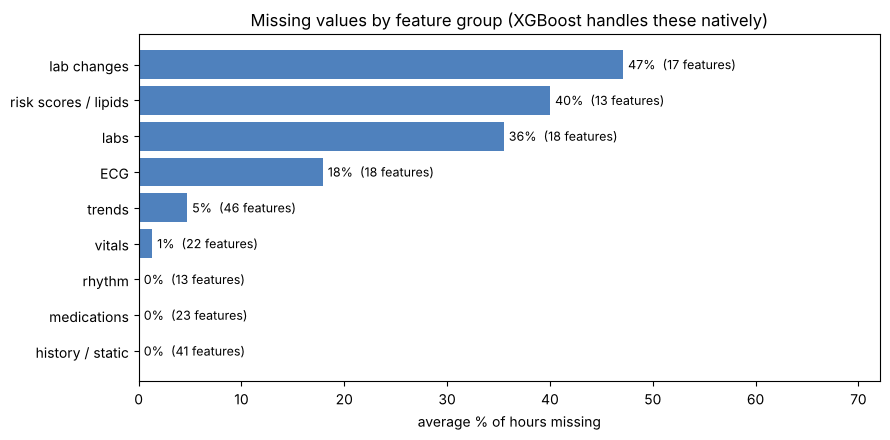

In [2]:
overview = pd.DataFrame({
    "rows (ICU hours)": [len(mf), len(train), (mf.split == "test").sum()],
    "patients": [mf.subject_id.nunique(), train.subject_id.nunique(), mf[mf.split == "test"].subject_id.nunique()],
    "ICU stays": [mf.stay_id.nunique(), train.stay_id.nunique(), mf[mf.split == "test"].stay_id.nunique()],
    "event hours (label_6h)": [mf.label_6h.sum(), train.label_6h.sum(), mf[mf.split == "test"].label_6h.sum()],
    "event rate %": [mf.label_6h.mean() * 100, train.label_6h.mean() * 100, mf[mf.split == "test"].label_6h.mean() * 100],
}, index=["all", "train", "test"]).round(2)
print(overview)
print("\nstays with at least one event hour:", mf.groupby("stay_id").label_6h.max().sum(), "of", mf.stay_id.nunique())

# feature groups and how much is missing in each
def group(c):
    if c.startswith("lab_chg_"): return "lab changes"
    if c.startswith("lab_"): return "labs"
    if c.startswith(("on_", "n_", "ix_", "dup_", "max_pct")) or c == "tisdale_score": return "medications"
    if c.startswith(("ecg_", "log_sdnn", "log_rmssd", "rr_cv", "pnn50", "r_amp", "has_ecg", "hours_since_ecg", "qtc_", "qrs_", "st_",
                     "t_inv", "pathologic_q", "irregular_rr", "lvh_", "sokolow", "hours_since_12lead")): return "ECG"
    if c.startswith(("rhythm_", "af_", "brady_", "tachy_", "paced_")): return "rhythm"
    if c.startswith(("hist_", "hx_", "smoker", "fam_hx", "hyperlip", "obesity", "prior_mi", "cad_hist", "admission_type", "race_",
                     "age_", "gender", "bmi", "weight_lbs", "height", "log_prior", "days_since", "diabetes", "ckd")): return "history / static"
    if c in ("cha2ds2_vasc", "has_bled_partial", "egfr", "ascvd_10y_risk", "total_chol", "hdl", "ldl", "triglycerides", "non_hdl",
             "tc_hdl_ratio", "hba1c", "sbp_outpatient", "dbp_outpatient"): return "risk scores / lipids"
    if any(k in c for k in ("_mean6h", "_min6h", "_max6h", "_delta6h", "_lag1", "_vs_baseline", "_24h", "_72h")): return "trends"
    return "vitals"
groups = pd.Series({c: group(c) for c in FEATURES})
miss = pd.DataFrame({"features": groups.value_counts(),
                     "% missing (mean)": groups.groupby(groups).apply(lambda g: mf[g.index].isna().mean().mean() * 100).round(1)})
print(miss.sort_values("features", ascending=False))
fig, ax = plt.subplots(figsize=(9, 4.5))
m = miss.sort_values("% missing (mean)")
ax.barh(m.index, m["% missing (mean)"], color=BLUE)
for i, (v, n) in enumerate(zip(m["% missing (mean)"], m.features)):
    ax.text(v + .5, i, f"{v:.0f}%  ({n} features)", va="center", fontsize=9)
ax.set_xlabel("average % of hours missing"); ax.set_title("Missing values by feature group (XGBoost handles these natively)")
ax.set_xlim(0, max(m["% missing (mean)"]) + 25)
savefig("01_missing_by_group")

**Result:** 86 patients and 112 ICU stays. **103 event hours (2.3%)**, from 35 stays with at least one. The event rate is the same in train (2.28%) and test (2.31%), so the split is fair. Labs (35%), lab changes (47%) and lipids/risk scores (40%) have the most gaps, because they are measured only now and then. XGBoost handles missing values natively, and the gaps themselves carry signal: sicker patients get more tests. Saved `01_missing_by_group.png`.

# 2 · Remove duplicate, empty and constant columns

**What this cell does (removes duplicate columns):**
1. **Constant** columns (one value on all train rows) and **empty** ones.
2. **Exact duplicates:** two columns with the same value in every row.
3. **Near-duplicates** among the new features (|r| > 0.98 on train).

It then saves the reduced table as **`features/model_final.csv`** and the feature list as **`features/final_config.json`**. Train on these from now on.

In [3]:
X = mf[FEATURES]
tr = train[FEATURES]
# 1) empty or constant on the train rows
empty = [c for c in FEATURES if tr[c].notna().sum() == 0]
constant = [c for c in FEATURES if c not in empty and tr[c].nunique(dropna=True) <= 1]
# 2) exact duplicates: same value in every row (NaN counts as equal)
key = {c: pd.util.hash_pandas_object(X[c].astype(float).fillna(-999999), index=False).sum() for c in FEATURES}
seen, exact_dup = {}, {}
for c in [c for c in FEATURES if c not in empty + constant]:
    if key[c] in seen and X[c].astype(float).fillna(-999999).equals(X[seen[key[c]]].astype(float).fillna(-999999)):
        exact_dup[c] = seen[key[c]]
    else:
        seen.setdefault(key[c], c)
# 3) near-duplicates among the NEW notebook-03 features (|r| > 0.98 on train, measured together in >= 300 hours)
new = [c for c in fconf["new_cardiac_features"] if c in FEATURES and c not in exact_dup and c not in empty + constant]
corr = tr[[c for c in FEATURES if c not in exact_dup and c not in empty + constant]].corr(min_periods=300).abs()
near_dup = {}
for c in new:
    others = corr[c].drop(c).dropna()
    others = others[(others > 0.98) & ~others.index.isin(list(near_dup))]
    if len(others):
        near_dup[c] = f"{others.idxmax()} (r = {others.max():.3f})"
DROP = sorted(set(exact_dup) | set(empty) | set(constant) | set(near_dup))
FINAL = [c for c in FEATURES if c not in DROP]
print("exact duplicates (dropped -> kept twin):", exact_dup)
print("empty on train:", empty)
print("constant on train:", constant)
print("near-duplicates (dropped -> kept twin):", near_dup)
print(f"\n{len(FEATURES)} features -> {len(FINAL)} after removing {len(DROP)}")

model_final = mf[ID_COLS + FINAL]
model_final.to_csv(FEAT / "model_final.csv", index=False)
model_final.to_pickle(FEAT / "model_final.pkl")
final_conf = dict(fconf, features=FINAL, dropped_in_eda={"exact_duplicates": exact_dup, "empty": empty, "constant": constant,
                                                          "near_duplicates": near_dup})
final_conf["scaler"] = {k: v for k, v in fconf["scaler"].items() if k in FINAL}
(FEAT / "final_config.json").write_text(json.dumps(final_conf, indent=1))
print("saved features/model_final.csv", model_final.shape, "and features/final_config.json")
FEATURES = FINAL
train = model_final[model_final.split == "train"]

exact duplicates (dropped -> kept twin): {'n_qt_known': 'n_qt_drugs'}
empty on train: []
constant on train: ['ix_hyperkalemia', 'ix_bradycardia', 'ix_digoxin_amiodarone']
near-duplicates (dropped -> kept twin): {'hours_since_12lead': 'hours_since_ecg (r = 1.000)', 'n_antiplatelet': 'on_antiplatelet (r = 0.989)'}

211 features -> 205 after removing 6


saved features/model_final.csv (4503, 213) and features/final_config.json


**Result:** **211 features, 205 kept, 6 removed:** `n_qt_known` (identical to `n_qt_drugs`), `ix_hyperkalemia`, `ix_bradycardia` and `ix_digoxin_amiodarone` (always 0 in train), `hours_since_12lead` (identical to `hours_since_ecg`), and `n_antiplatelet` (r = 0.99 with `on_antiplatelet`).

# 3 · The label: how often does deterioration happen?

**What this cell does:** charts the label: event rate per split, what the first deterioration was, and ICU stay length with and without an event.

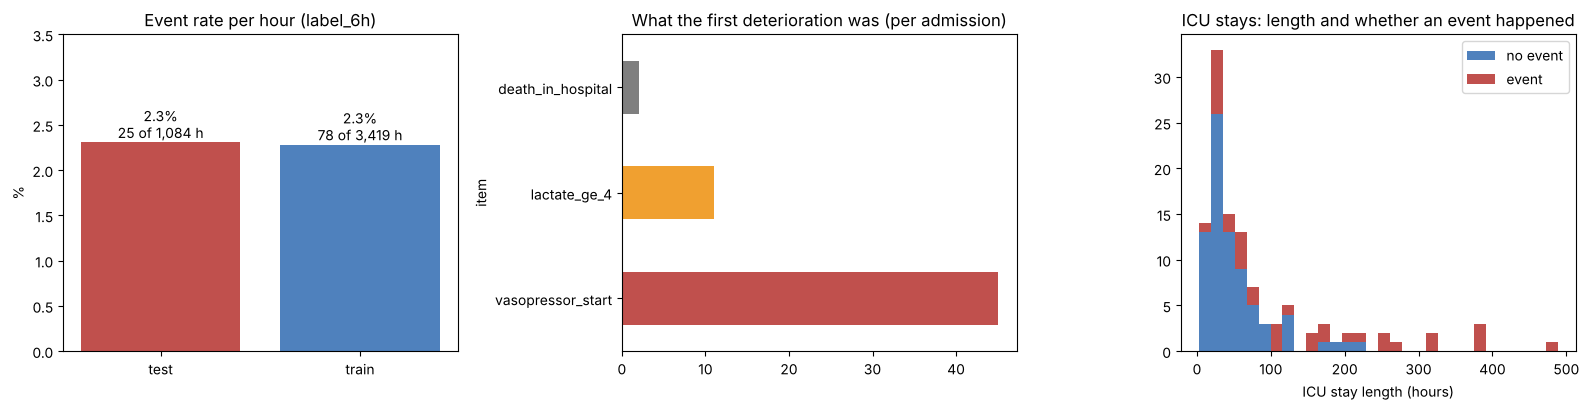

item
vasopressor_start    45
lactate_ge_4         11
death_in_hospital     2
Name: count, dtype: int64


In [4]:
ev = clinical_clean[(clinical_clean.source == "event") & clinical_clean.item.isin(["vasopressor_start", "lactate_ge_4", "death_in_hospital"])]
first = ev.sort_values("time").groupby("hadm_id").first()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
s = model_final.groupby("split").label_6h.agg(["mean", "sum", "size"])
axes[0].bar(s.index, s["mean"] * 100, color=[RED, BLUE])
for i, (r, n, t) in enumerate(zip(s["mean"], s["sum"], s["size"])):
    axes[0].text(i, r * 100 + .05, f"{r:.1%}\n{n} of {t:,} h", ha="center")
axes[0].set_ylim(0, 3.5); axes[0].set_title("Event rate per hour (label_6h)"); axes[0].set_ylabel("%")
first.item.value_counts().plot.barh(ax=axes[1], color=[RED, "#f0a030", GREY])
axes[1].set_title("What the first deterioration was (per admission)")
stay_len = dynamic_clean.groupby("stay_id").hours_since_icu_admit.max()
ev_stays = model_final.groupby("stay_id").label_6h.max()
axes[2].hist([stay_len[ev_stays.index[ev_stays == 0]], stay_len[ev_stays.index[ev_stays == 1]]], bins=30, stacked=True,
             color=[BLUE, RED], label=["no event", "event"])
axes[2].set_xlabel("ICU stay length (hours)"); axes[2].set_title("ICU stays: length and whether an event happened"); axes[2].legend()
savefig("02_label_overview")
print(first.item.value_counts())

**Result:** the first deterioration was a **vasopressor start in 45 admissions**, lactate ≥ 4 in 11 and death in 2. Stays with an event tend to be longer. Saved `02_label_overview.png`.

# 4 · Event rate by risk factor

**What this cell does (event rate by risk factor):** for each yes/no risk factor, the % of train hours followed by deterioration within 6 h, with and without the factor, plus the **relative risk** (how many times higher). Factors held by fewer than 10 patients are greyed out, because they are too few to trust.

              risk factor  patients with it  hours  event rate if yes %  event rate if no %  relative risk
    Family history of CAD                 6     53                24.53                1.93          12.70
                   Smoker                31    911                 6.26                0.84           7.47
                     Male                39   1187                 4.55                1.08           4.23
               AF history                 7    181                 7.73                1.98           3.91
Prior MI / stent / bypass                10    207                 6.76                1.99           3.39
            Valve disease                10    338                 5.92                1.88           3.14
                      CKD                20    520                 4.81                1.83           2.63
          Hyperlipidaemia                39   1610                 3.35                1.33           2.53
    Heart failure history            

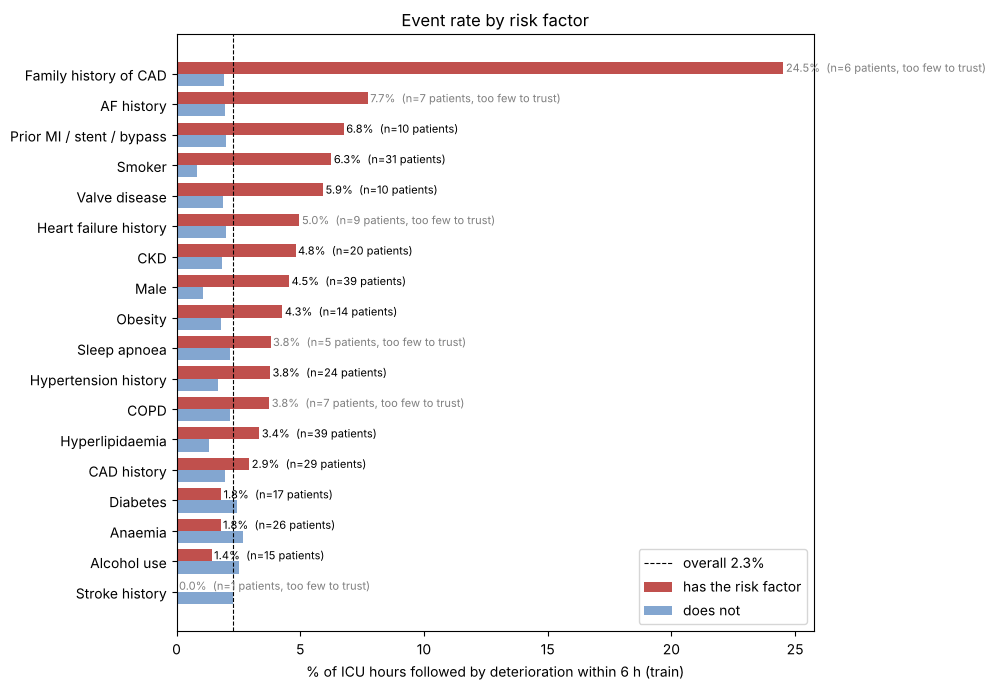

In [5]:
# yes/no risk factors (train hours): how much more often is the next 6 h an event when the factor is present?
RISK = {"Smoker": "smoker", "CAD history": "cad_history", "Prior MI / stent / bypass": "prior_mi_or_revasc",
        "Family history of CAD": "fam_hx_cad", "Hyperlipidaemia": "hyperlipidemia", "Obesity": "obesity", "Diabetes": "diabetes",
        "CKD": "ckd", "Heart failure history": "hist_hf", "AF history": "hist_af", "Hypertension history": "hist_htn",
        "Stroke history": "hist_stroke", "COPD": "hx_copd", "Sleep apnoea": "hx_sleep_apnea", "Alcohol use": "hx_alcohol_use",
        "Valve disease": "hx_valve_disease", "Anaemia": "hx_anemia_dx", "Male": "gender_male"}
base = train.label_6h.mean() * 100
rows = []
for name, col in RISK.items():
    if col not in train: continue
    yes = train[train[col] == 1]
    rows.append({"risk factor": name, "patients with it": yes.subject_id.nunique(), "hours": len(yes),
                 "event rate if yes %": yes.label_6h.mean() * 100, "event rate if no %": train[train[col] != 1].label_6h.mean() * 100})
rf = pd.DataFrame(rows)
rf["relative risk"] = (rf["event rate if yes %"] / rf["event rate if no %"]).round(2)
rf = rf.sort_values("relative risk", ascending=False).round(2)
print(rf.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 7))
r = rf.sort_values("event rate if yes %")
yy = np.arange(len(r))
ax.barh(yy + .2, r["event rate if yes %"], height=.4, color=RED, label="has the risk factor")
ax.barh(yy - .2, r["event rate if no %"], height=.4, color=BLUE, alpha=.7, label="does not")
ax.set_yticks(yy); ax.set_yticklabels(r["risk factor"])
ax.axvline(base, color="k", ls="--", lw=.8, label=f"overall {base:.1f}%")
for i, (y, n) in enumerate(zip(r["event rate if yes %"], r["patients with it"])):
    ax.text(y + .1, i + .2, f"{y:.1f}%  (n={n} patients{', too few to trust' if n < 10 else ''})", va="center", fontsize=8,
            color="k" if n >= 10 else GREY)
ax.set_xlabel("% of ICU hours followed by deterioration within 6 h (train)"); ax.legend(loc="lower right")
ax.set_title("Event rate by risk factor")
savefig("03_event_rate_by_risk_factor")

**Result:** with a reliable number of patients, the highest-risk factors are **prior MI / stent / bypass (3.4x, 10 patients)**, **smoking (7.5x: 6.3% vs 0.8%, 31 patients)**, valve disease (3.1x), CKD (2.6x), male sex (4.2x), hyperlipidaemia (2.5x), obesity (2.4x) and hypertension (2.3x). **Family history of CAD shows 12.7x but covers only 6 patients**, so it is a hint, not proof. Diabetes, anaemia and alcohol show *lower* short-term rates in this small ICU sample; they are long-term risks, not 6-hour deterioration triggers. Saved `03_event_rate_by_risk_factor.png`.

**What this cell does:** event rate by **level** of age, NEWS, shock index, lactate, QTc, MAP, SpO2 and eGFR, using clinical cut-offs. Red bars are more than 1.5 times the overall rate.

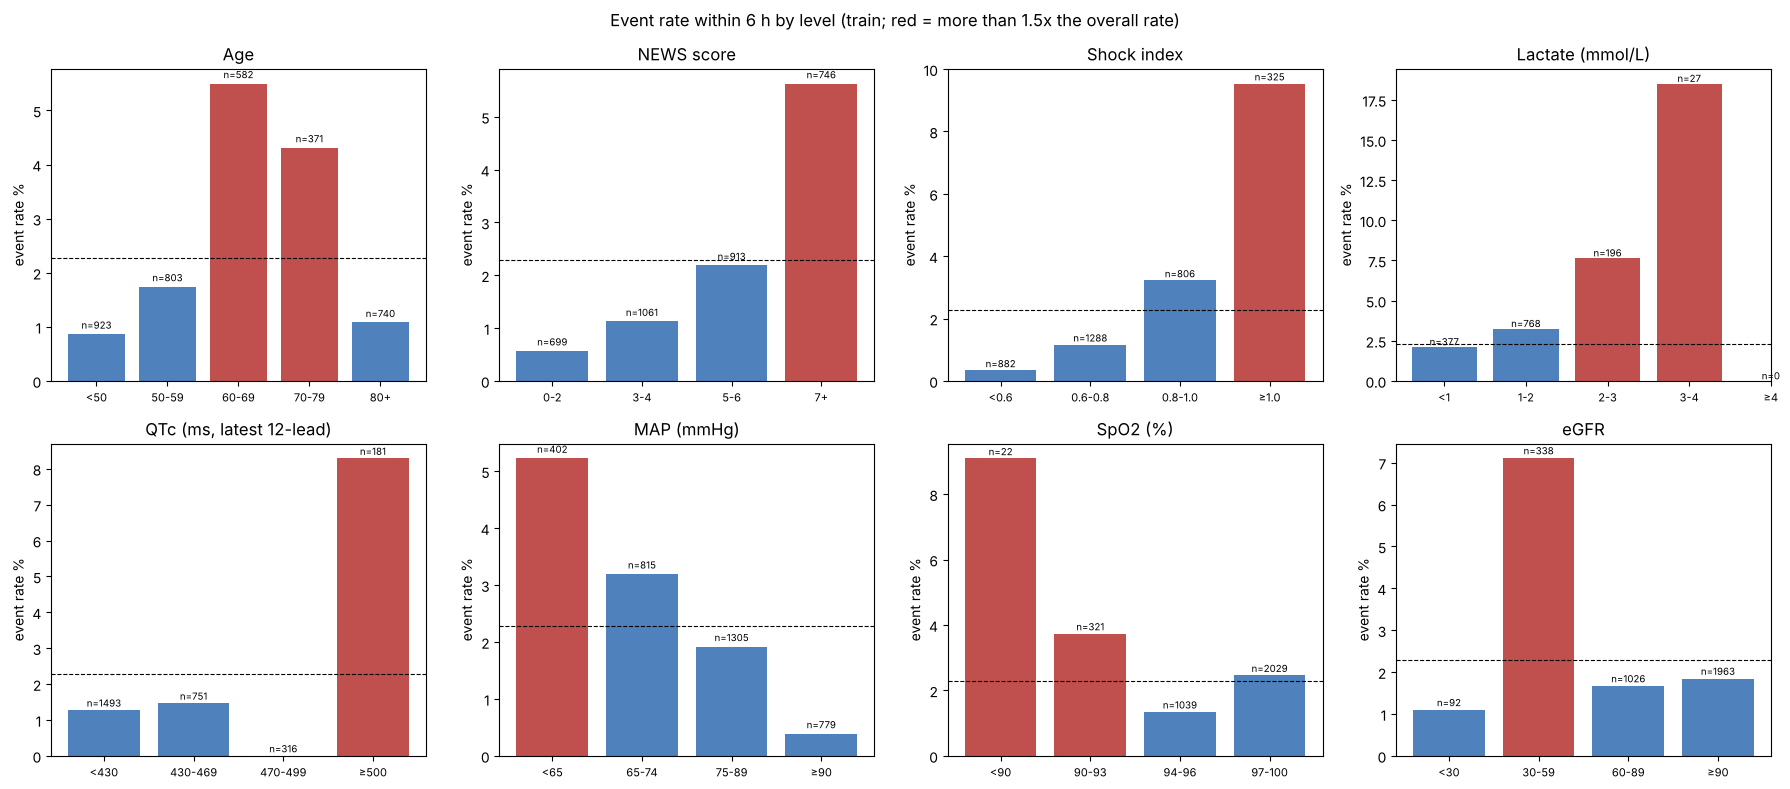

In [6]:
# continuous features: event rate by level (quintiles, or clinical bands)
BANDS = {
    "age_at_admit":  ([0, 50, 60, 70, 80, 120], ["<50", "50-59", "60-69", "70-79", "80+"]),
    "news_score":    ([-1, 2, 4, 6, 30], ["0-2", "3-4", "5-6", "7+"]),
    "shock_index":   ([0, .6, .8, 1.0, 9], ["<0.6", "0.6-0.8", "0.8-1.0", "≥1.0"]),
    "lab_log_lactate": (np.log1p([0, 1, 2, 3, 4, 50]), ["<1", "1-2", "2-3", "3-4", "≥4"]),
    "qtc_bazett_ms": ([0, 430, 470, 500, 900], ["<430", "430-469", "470-499", "≥500"]),
    "map":           ([0, 65, 75, 90, 300], ["<65", "65-74", "75-89", "≥90"]),
    "spo2":          ([0, 90, 94, 97, 101], ["<90", "90-93", "94-96", "97-100"]),
    "egfr":          ([0, 30, 60, 90, 300], ["<30", "30-59", "60-89", "≥90"]),
}
TITLES = {"age_at_admit": "Age", "news_score": "NEWS score", "shock_index": "Shock index", "lab_log_lactate": "Lactate (mmol/L)",
          "qtc_bazett_ms": "QTc (ms, latest 12-lead)", "map": "MAP (mmHg)", "spo2": "SpO2 (%)", "egfr": "eGFR"}
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (col, (bins, labels)) in zip(axes.flat, BANDS.items()):
    b = pd.cut(train[col], bins, labels=labels, right=False)
    t = train.groupby(b, observed=False).label_6h.agg(["mean", "size"])
    ax.bar(range(len(t)), t["mean"] * 100, color=[RED if v * 100 > base * 1.5 else BLUE for v in t["mean"].fillna(0)])
    ax.set_xticks(range(len(t))); ax.set_xticklabels(t.index, fontsize=8)
    for i, (v, n) in enumerate(zip(t["mean"].fillna(0), t["size"])):
        ax.text(i, v * 100 + .1, f"n={n}", ha="center", fontsize=7)
    ax.axhline(base, color="k", ls="--", lw=.8); ax.set_title(TITLES[col]); ax.set_ylabel("event rate %")
fig.suptitle("Event rate within 6 h by level (train; red = more than 1.5x the overall rate)", fontsize=12)
savefig("04_event_rate_by_level")

**Result:** clear dose-response patterns:
- **NEWS 7+: 5.6%** vs 0.6% at 0-2
- **Shock index ≥ 1.0: 9.5%** vs 0.3% below 0.6
- **Lactate 3-4: 18.5%**
- **QTc ≥ 500: 8.3%**
- **MAP < 65: 5.2%**
- **SpO2 < 90: 9.1%**

Age 60-79 and eGFR 30-59 are also higher. There are no lactate ≥ 4 hours, because lactate ≥ 4 *is* an event and later hours were removed. Saved `04_event_rate_by_level.png`.

# 5 · Vitals in the 24 hours before an event

**What this cell does (vitals in the 24 h before an event):** lines up all 28 train stays with an event on the hour of their first deterioration (hour 0) and plots the average of each vital over the 24 h before, with a 95% confidence band. For comparison it plots 58 event-free stays over a 24 h window from the middle of their stay.

stays with an event (train): 28 | event-free stays (train): 58


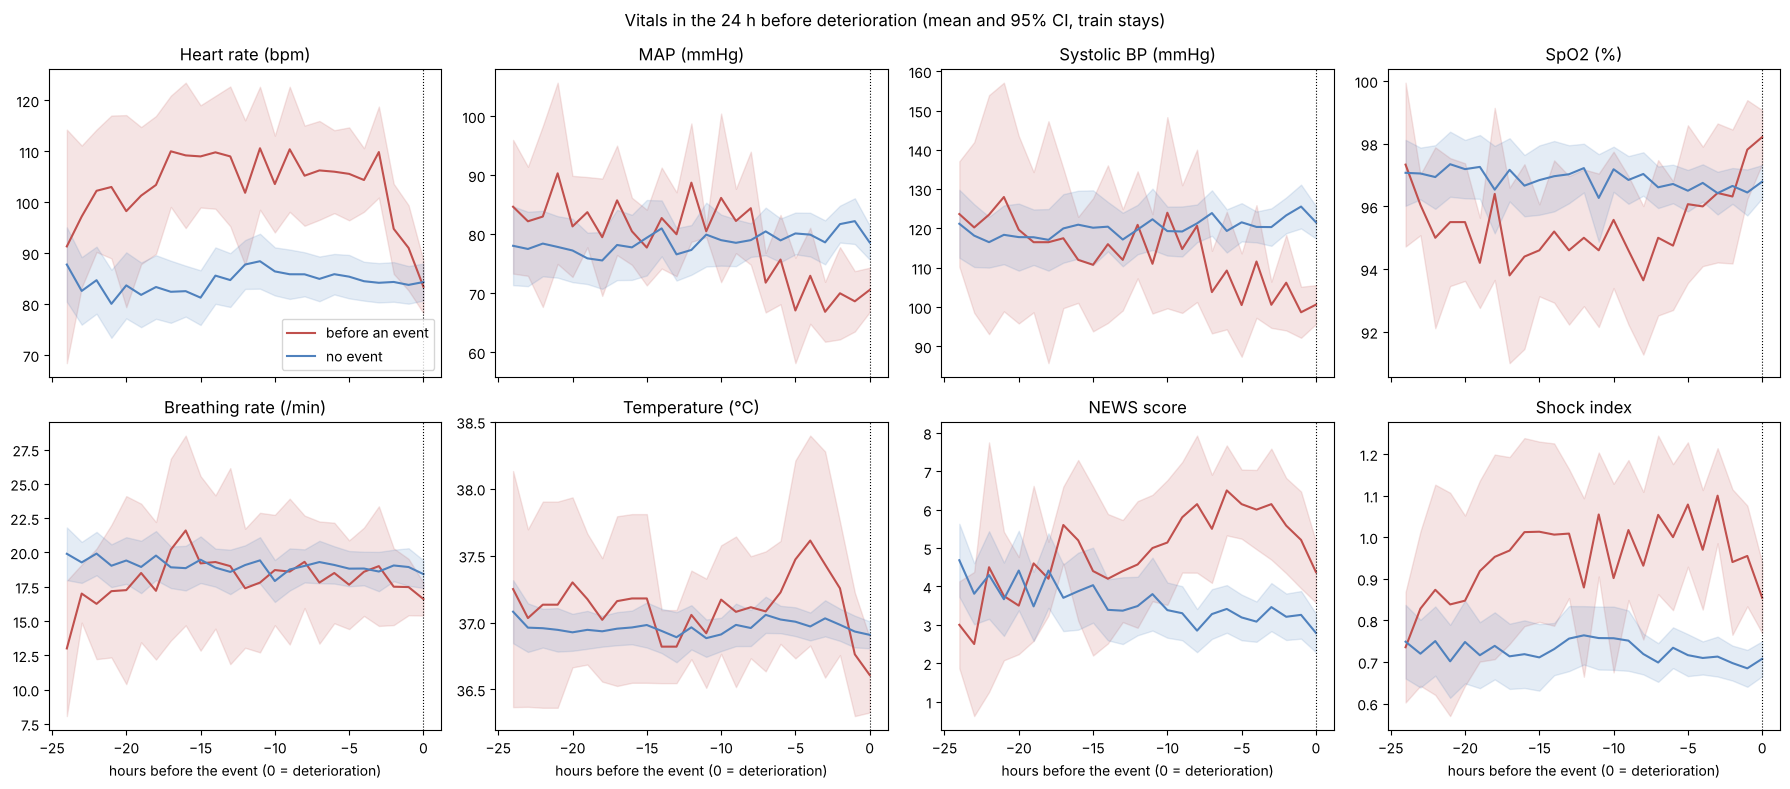

             event: 24 h before  event: last 6 h  no event
hr                       100.01            93.95     84.74
map                       83.31            70.23     79.04
sbp                      120.84           102.73    120.55
spo2                      95.63            97.09     96.81
rr                        16.83            17.50     18.97
temp_c                    37.14            37.02     36.97
news_score                 3.79             5.30      3.46
shock_index                0.86             0.94      0.72


In [7]:
# align every stay with an event on the hour of its first deterioration (hour 0), and compare with stays with no event
d = dynamic_clean.merge(hourly[["stay_id", "hour", "af_burden_24h", "weight_change_72h"]], on=["stay_id", "hour"], how="left")
d["t_event"] = d.hadm_id.map(first.time)
d["h_to_event"] = ((d.hour - d.t_event).dt.total_seconds() / 3600).round()
train_stays = set(train.stay_id)
case = d[d.stay_id.isin(train_stays) & d.h_to_event.between(-24, 0)]
ctrl_stays = [s for s in train_stays if s not in set(case.stay_id) and d[d.stay_id == s].t_event.isna().all()]
# controls: a 24 h window from the middle of each event-free stay, aligned the same way
ctrl = d[d.stay_id.isin(ctrl_stays)].copy()
mid = ctrl.groupby("stay_id").hours_since_icu_admit.transform(lambda x: x.median().round())
ctrl["h_to_event"] = (ctrl.hours_since_icu_admit - mid).round()
ctrl = ctrl[ctrl.h_to_event.between(-24, 0)]
print("stays with an event (train):", case.stay_id.nunique(), "| event-free stays (train):", ctrl.stay_id.nunique())

VITALS = [("hr", "Heart rate (bpm)"), ("map", "MAP (mmHg)"), ("sbp", "Systolic BP (mmHg)"), ("spo2", "SpO2 (%)"),
          ("rr", "Breathing rate (/min)"), ("temp_c", "Temperature (°C)"), ("news_score", "NEWS score"), ("shock_index", "Shock index")]
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=True)
summary = {}
for ax, (col, title) in zip(axes.flat, VITALS):
    for df, colr, lab in [(case, RED, "before an event"), (ctrl, BLUE, "no event")]:
        g = df.groupby("h_to_event")[col]
        mu, se = g.mean(), g.std() / np.sqrt(g.count())
        ax.plot(mu.index, mu, color=colr, label=lab)
        ax.fill_between(mu.index, mu - 1.96 * se, mu + 1.96 * se, color=colr, alpha=.15)
    ax.set_title(title); ax.axvline(0, color="k", ls=":", lw=.8)
    summary[col] = {"event: 24 h before": case[case.h_to_event.between(-24, -18)][col].mean(),
                    "event: last 6 h": case[case.h_to_event.between(-6, 0)][col].mean(),
                    "no event": ctrl[col].mean()}
for ax in axes[1]: ax.set_xlabel("hours before the event (0 = deterioration)")
axes[0, 0].legend()
fig.suptitle("Vitals in the 24 h before deterioration (mean and 95% CI, train stays)", fontsize=12)
savefig("05_vitals_24h_before_event")
print(pd.DataFrame(summary).T.round(2))

**Result:** the twin's warning signs are visible **hours in advance**:
- **Heart rate:** stays about 100-110 vs 85 for most of the day, then falls just before the event.
- **MAP:** drops from about 83 to **70 mmHg** in the last 6 h, and **systolic BP from 121 to 103**.
- **NEWS:** climbs from 3.8 to **5.3 on average, peaking above 6** in the hours before.
- **Shock index:** rises from 0.86 to 0.94 (0.72 in event-free stays).

Breathing rate and temperature barely differ. Saved `05_vitals_24h_before_event.png`.

**What this cell does:** draws one real patient's 48 hours before deterioration: HR, BP, SpO2, and NEWS coloured by alert tier (red ≥ 7, amber 5-6).

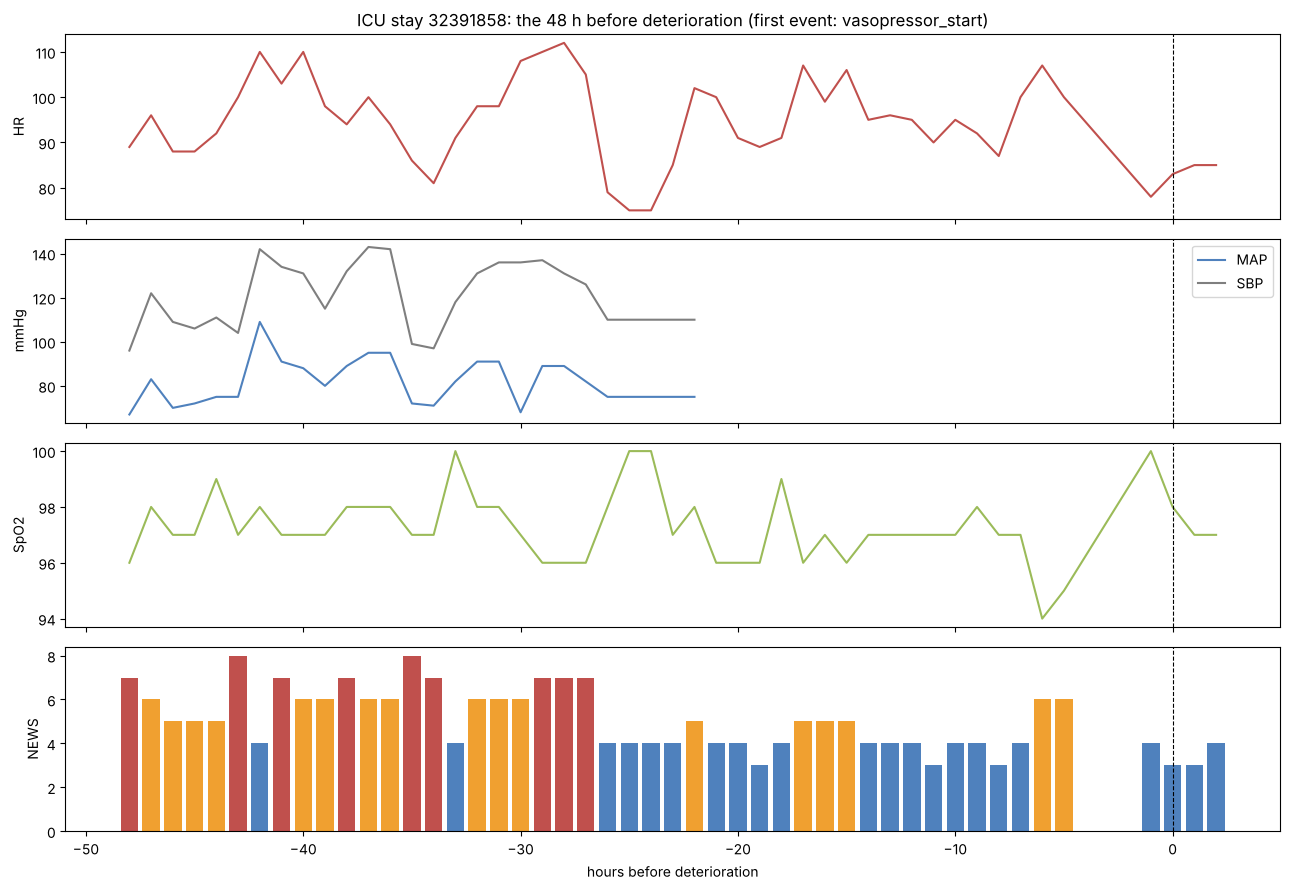

In [8]:
# one real patient's twin view: vitals + NEWS + AF in the 48 h before the event
sid = d[d.stay_id.isin(case.stay_id) & d.h_to_event.between(-48, 0)].groupby("stay_id").h_to_event.min().idxmin()
p = d[(d.stay_id == sid) & d.h_to_event.between(-48, 2)]
fig, axes = plt.subplots(4, 1, figsize=(13, 9), sharex=True)
axes[0].plot(p.h_to_event, p.hr, color=RED); axes[0].set_ylabel("HR")
axes[1].plot(p.h_to_event, p["map"], color=BLUE, label="MAP"); axes[1].plot(p.h_to_event, p.sbp, color=GREY, label="SBP"); axes[1].legend(); axes[1].set_ylabel("mmHg")
axes[2].plot(p.h_to_event, p.spo2, color="#9bbb59"); axes[2].set_ylabel("SpO2")
axes[3].bar(p.h_to_event, p.news_score, color=np.where(p.news_score >= 7, RED, np.where(p.news_score >= 5, "#f0a030", BLUE)))
axes[3].set_ylabel("NEWS"); axes[3].set_xlabel("hours before deterioration")
for a in axes: a.axvline(0, color="k", ls="--", lw=.8)
axes[0].set_title(f"ICU stay {sid}: the 48 h before deterioration (first event: {first.loc[p.hadm_id.iloc[0], 'item']})")
savefig("06_patient_example_48h")

**Result:** in this stay **NEWS is red repeatedly from about 12 h before the vasopressor was started**, while blood pressure drifts down. This is the story the twin demo tells. Saved `06_patient_example_48h.png`.

# 6 · Distributions: event vs no event

**What this cell does:** boxplots of 12 key features for hours followed by an event vs not (outliers hidden).

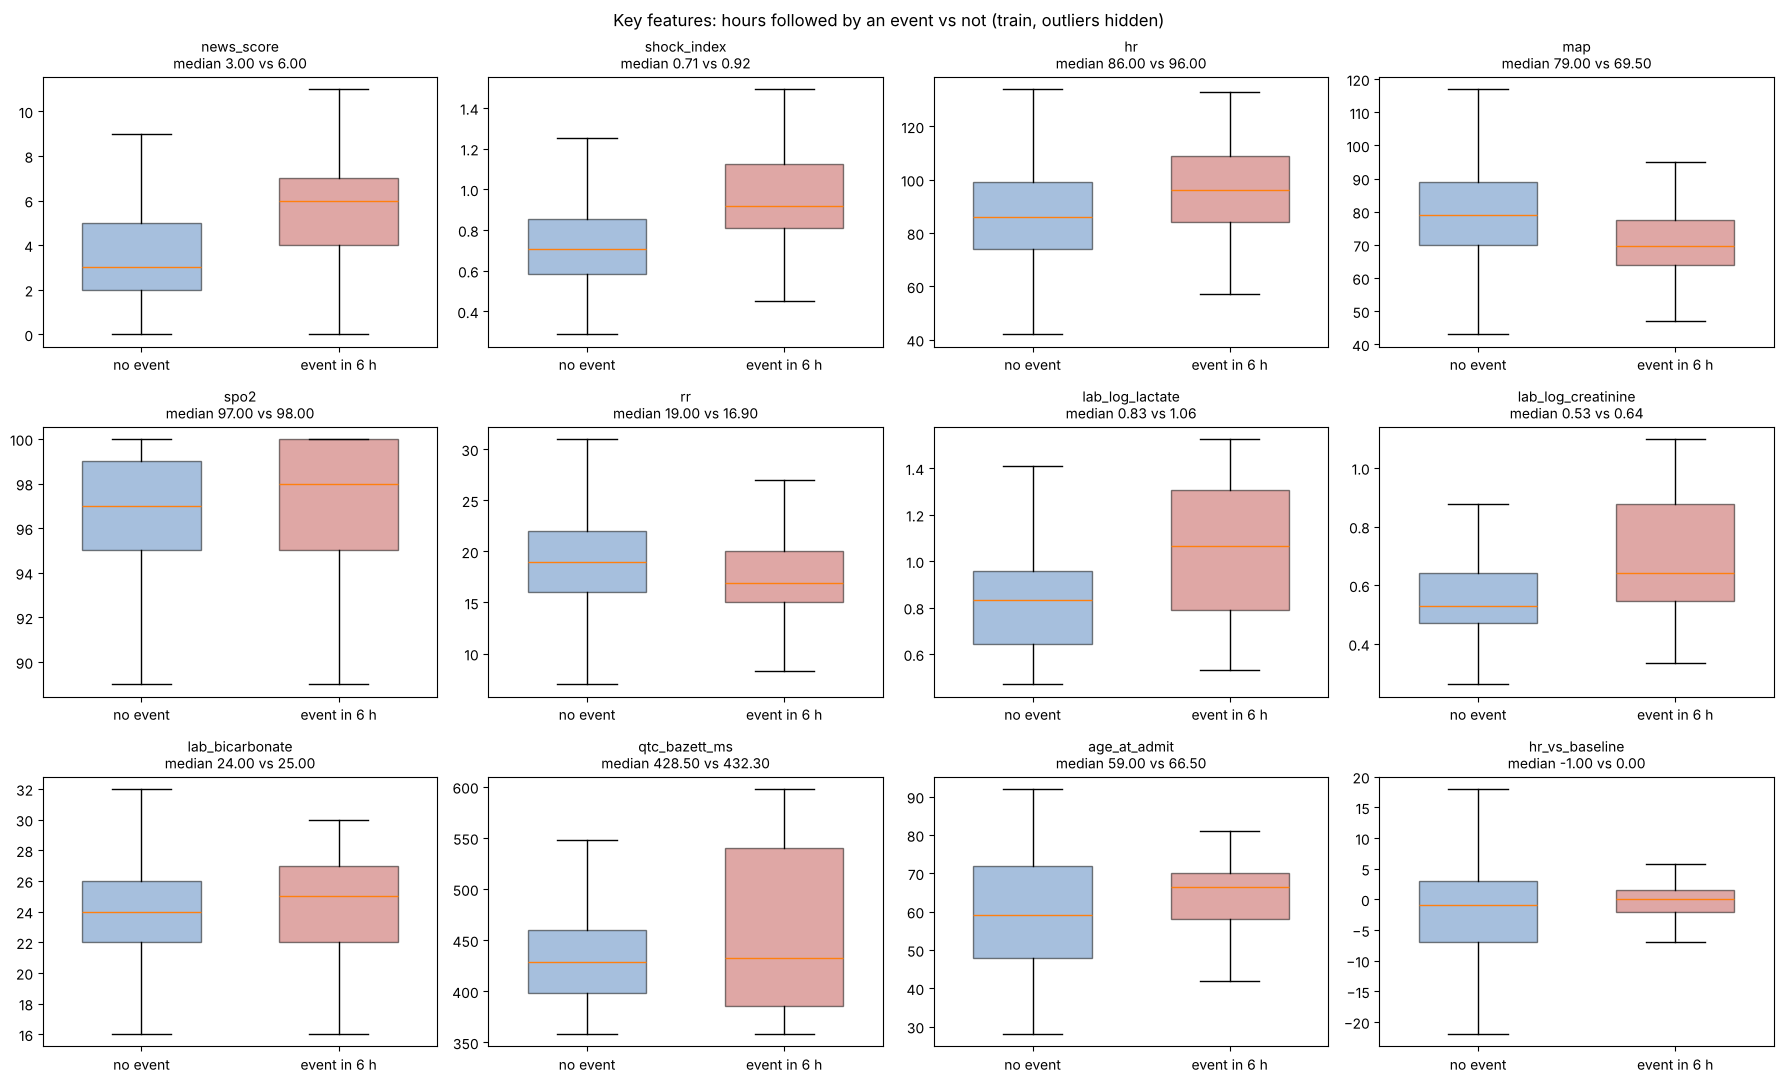

In [9]:
KEY = ["news_score", "shock_index", "hr", "map", "spo2", "rr", "lab_log_lactate", "lab_log_creatinine", "lab_bicarbonate",
       "qtc_bazett_ms", "age_at_admit", "hr_vs_baseline"]
KEY = [c for c in KEY if c in train]
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, col in zip(axes.flat, KEY):
    a, b = train.loc[train.label_6h == 0, col].dropna(), train.loc[train.label_6h == 1, col].dropna()
    bp = ax.boxplot([a, b], showfliers=False, patch_artist=True, widths=.6)
    ax.set_xticks([1, 2]); ax.set_xticklabels(["no event", "event in 6 h"])
    for patch, c in zip(bp["boxes"], [BLUE, RED]): patch.set_facecolor(c); patch.set_alpha(.5)
    ax.set_title(f"{col}\nmedian {a.median():.2f} vs {b.median():.2f}", fontsize=10)
fig.suptitle("Key features: hours followed by an event vs not (train, outliers hidden)", fontsize=12)
savefig("07_distributions_event_vs_no_event")

**Result:** event hours have higher NEWS, shock index, heart rate, lactate and creatinine, and lower MAP and bicarbonate. Each box title shows the two medians. Saved `07_distributions_event_vs_no_event.png`.

# 7 · Correlations and each feature's link with the label

**What this cell does:** scores every feature **on its own** with AUROC (0.5 = no signal, 1.0 or 0.0 = perfect, in either direction) and its correlation with the label. Features with fewer than 10 event hours or 300 measured hours are skipped as too sparse. The full ranking is saved to `features/eda_feature_ranking.csv`.

198 of 205 features have >= 10 event hours and >= 300 measured hours; the rest are too sparse to rank
                         auroc  corr_with_label  % missing  event hours measured  strength           direction             group
hr_trend_24h             0.830            0.086     35.186                    21     0.830  higher = more risk            trends
hours_since_icu_admit    0.192           -0.108      0.000                    78     0.808   lower = more risk            vitals
shock_index_lag1         0.803            0.172      6.054                    54     0.803  higher = more risk            trends
sbp_max6h                0.212           -0.151      2.866                    75     0.788   lower = more risk            trends
sbp                      0.218           -0.147      3.451                    75     0.782   lower = more risk            vitals
map_max6h                0.221           -0.141      2.866                    75     0.779   lower = more risk            tr

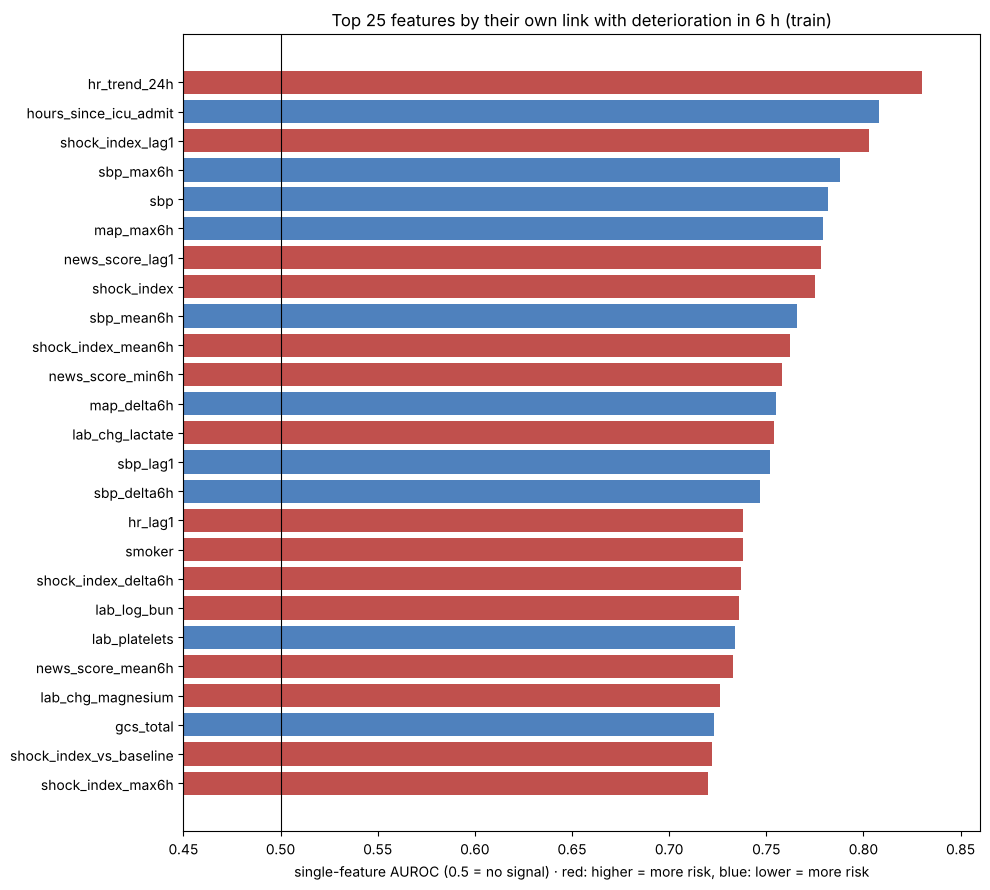

In [10]:
def auroc(y, s):
    ok = s.notna()
    y, s = y[ok], s[ok].rank()
    n1, n0 = y.sum(), len(y) - y.sum()
    if n1 == 0 or n0 == 0: return np.nan
    return (s[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

y = train.label_6h
events_measured = {c: int(y[train[c].notna()].sum()) for c in FEATURES}
ok = [c for c in FEATURES if events_measured[c] >= 10 and train[c].notna().sum() >= 300]   # enough data to judge
print(f"{len(ok)} of {len(FEATURES)} features have >= 10 event hours and >= 300 measured hours; the rest are too sparse to rank")
rank = pd.DataFrame({"auroc": {c: auroc(y, train[c].astype(float)) for c in ok},
                     "corr_with_label": train[ok].astype(float).corrwith(y),
                     "% missing": train[ok].isna().mean() * 100,
                     "event hours measured": pd.Series(events_measured)[ok]})
rank["strength"] = (rank.auroc - .5).abs() + .5            # 0.5 = no signal; direction doesn't matter here
rank["direction"] = np.where(rank.auroc >= .5, "higher = more risk", "lower = more risk")
rank["group"] = groups.reindex(rank.index)
rank = rank.sort_values("strength", ascending=False).round(3)
rank.to_csv(FEAT / "eda_feature_ranking.csv")
print(rank.head(25).to_string())

top = rank.head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(top.index, top.strength, color=[RED if d.startswith("higher") else BLUE for d in top.direction])
ax.axvline(.5, color="k", lw=.8); ax.set_xlim(.45, max(.8, top.strength.max() + .03))
ax.set_xlabel("single-feature AUROC (0.5 = no signal) · red: higher = more risk, blue: lower = more risk")
ax.set_title("Top 25 features by their own link with deterioration in 6 h (train)")
savefig("08_top_features_univariate")

**Result:** 198 of 205 features have enough data. The strongest single signals are **24 h HR trend (0.83)**, **shock index (0.78-0.80, previous hour and current)**, **systolic BP and MAP (lower = risk, about 0.78)**, **NEWS (0.76-0.78)**, **rising lactate (0.75)**, **smoking (0.74)** and BUN. `hours_since_icu_admit` also scores high, because events happen early in a stay. No single feature is enough, which is why the model combines them. Saved `08_top_features_univariate.png`.

**What this cell does:** draws a correlation heatmap of the 30 strongest features plus the label, then lists the feature pairs with |r| > 0.8.

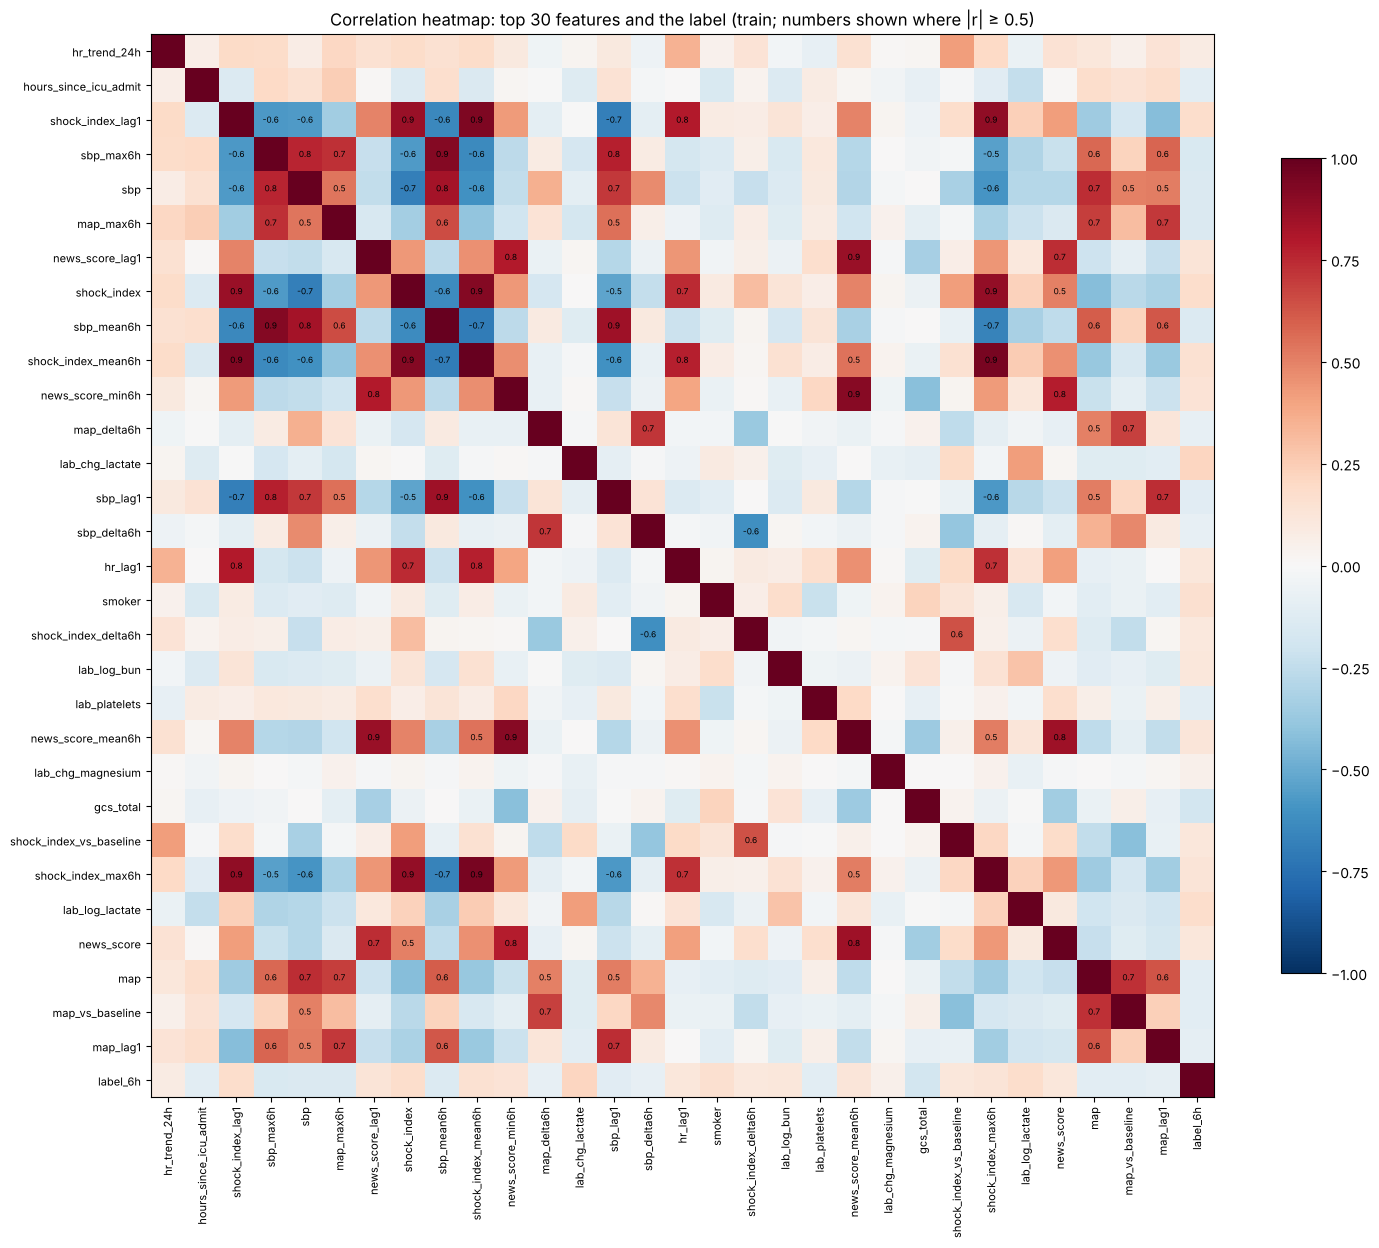

49 feature pairs with |r| > 0.8 (kept: tree models handle them; they matter only for linear models)
         feature A          feature B   |r|
shock_index_mean6h  shock_index_max6h 0.949
       on_diuretic    n_loop_diuretic 0.947
         hr_mean6h           hr_max6h 0.938
           hx_copd     hx_sleep_apnea 0.938
         hr_mean6h            hr_lag1 0.933
     af_burden_24h  af_burden_pct_24h 0.932
shock_index_mean6h   shock_index_lag1 0.932
  on_anticoagulant    n_anticoagulant 0.922
       shock_index shock_index_mean6h 0.921
        sbp_mean6h          sbp_max6h 0.917
 news_score_mean6h   news_score_max6h 0.916
                hr          hr_mean6h 0.915
   on_beta_blocker     n_beta_blocker 0.911
 news_score_mean6h   news_score_min6h 0.910
               dbp                map 0.908


In [11]:
# correlation heatmap: the 30 strongest features + the label
cols = list(rank.head(30).index) + ["label_6h"]
cm = train[cols].astype(float).corr(min_periods=200)
fig, ax = plt.subplots(figsize=(15, 13))
im = ax.imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=90, fontsize=8)
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols, fontsize=8)
for i in range(len(cols)):
    for j in range(len(cols)):
        v = cm.iloc[i, j]
        if v == v and abs(v) >= .5 and i != j:
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, shrink=.7); ax.set_title("Correlation heatmap: top 30 features and the label (train; numbers shown where |r| ≥ 0.5)")
savefig("09_correlation_heatmap_top30")

# clusters of strongly linked features (|r| > 0.8) the model will see as one signal
c2 = train[FEATURES].astype(float).corr(min_periods=300).abs()
pairs = [(a, b, c2.loc[a, b]) for i, a in enumerate(FEATURES) for b in FEATURES[i + 1:] if c2.loc[a, b] > .8]
pairs = pd.DataFrame(pairs, columns=["feature A", "feature B", "|r|"]).sort_values("|r|", ascending=False)
print(f"{len(pairs)} feature pairs with |r| > 0.8 (kept: tree models handle them; they matter only for linear models)")
print(pairs.head(15).round(3).to_string(index=False))

**Result:** the vitals form **tight clusters**: the shock index family, SBP/MAP/DBP, the NEWS family, and the HR family. **49 pairs have |r| > 0.8**, for example a drug flag and its count, or COPD and sleep apnoea. They are kept, because tree models handle correlated features; only a linear model would need them thinned. Saved `09_correlation_heatmap_top30.png`.

**What this cell does:** draws a correlation heatmap of the **cardiac risk factors and scores**, one row per admission (train).

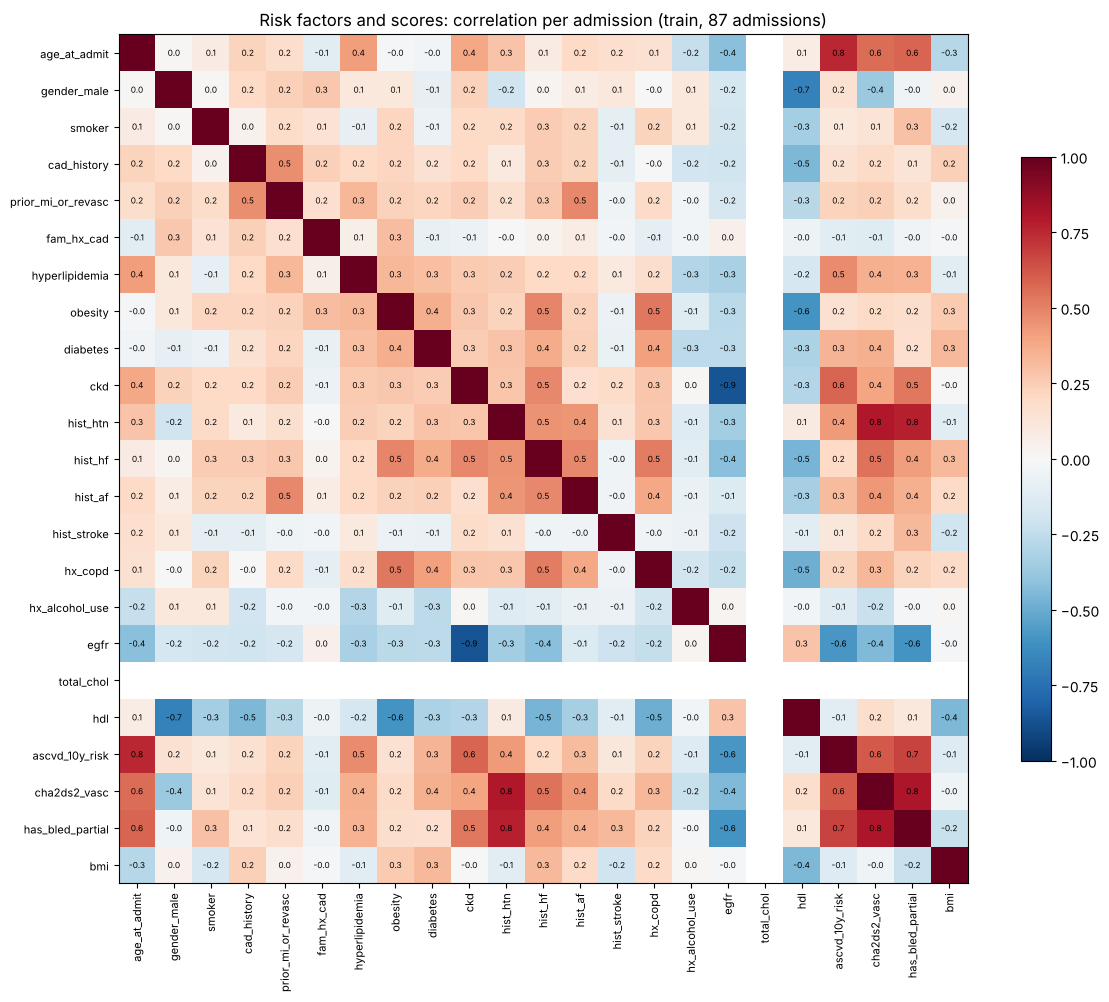

In [12]:
# heatmap of the cardiac risk factors and scores (patient-level view)
RF = ["age_at_admit", "gender_male", "smoker", "cad_history", "prior_mi_or_revasc", "fam_hx_cad", "hyperlipidemia", "obesity",
      "diabetes", "ckd", "hist_htn", "hist_hf", "hist_af", "hist_stroke", "hx_copd", "hx_alcohol_use", "egfr", "total_chol", "hdl",
      "ascvd_10y_risk", "cha2ds2_vasc", "has_bled_partial", "bmi"]
RF = [c for c in RF if c in model_final]
adm = model_final[model_final.split == "train"].groupby("hadm_id")[RF].first()
cm = adm.astype(float).corr(min_periods=30)
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(RF))); ax.set_xticklabels(RF, rotation=90, fontsize=8); ax.set_yticks(range(len(RF))); ax.set_yticklabels(RF, fontsize=8)
for i in range(len(RF)):
    for j in range(len(RF)):
        v = cm.iloc[i, j]
        if v == v and i != j: ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, shrink=.7); ax.set_title(f"Risk factors and scores: correlation per admission (train, {len(adm)} admissions)")
savefig("10_risk_factor_correlation")

**Result:** the scores agree with their parts as expected: ASCVD risk goes with age and male sex, CHA2DS2-VASc with age, HF, hypertension and diabetes, and eGFR against CKD. Smoking is only weakly linked with the other factors, so it adds its own information. Saved `10_risk_factor_correlation.png`.

# 8 · Train vs test: do they look alike?

**What this cell does (train vs test check):** compares the mean of every well-measured feature in test and train as a **standardised mean difference** (|d| > 0.25 = noticeably different).

features with |standardised mean difference| > 0.25: 33 of 118
height_in             1.03
triglycerides         0.76
lab_log_lactate       0.72
lab_log_creatinine    0.64
pnn50                 0.57
lab_potassium         0.53
lab_log_bun           0.53
lab_log_glucose       0.52
spo2_mean6h          -0.49
weight_kg             0.48
dtype: float64


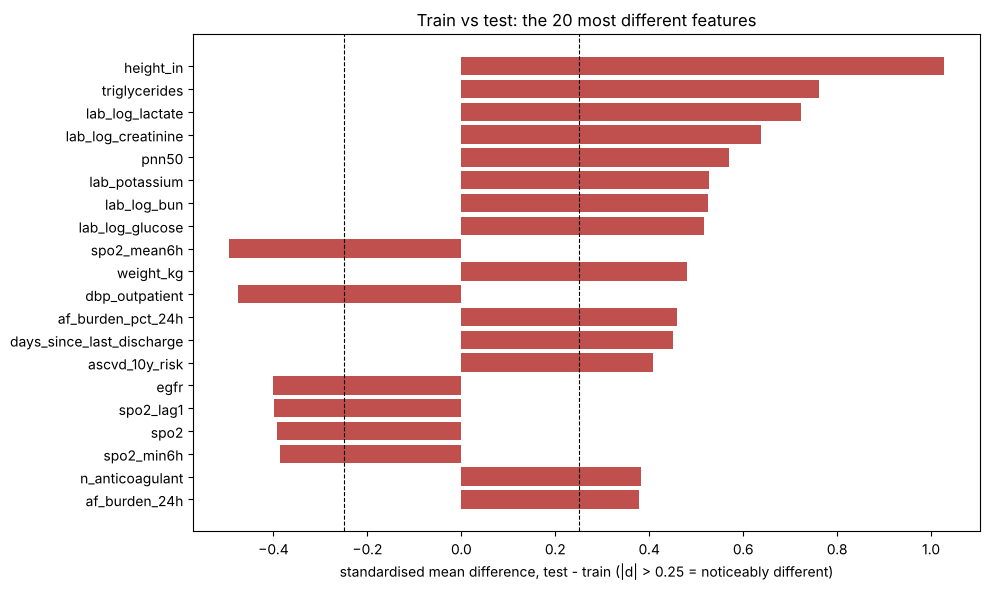

In [13]:
te = model_final[model_final.split == "test"]
num = [c for c in FEATURES if model_final[c].nunique() > 2 and train[c].notna().mean() > .3 and te[c].notna().mean() > .3]
smd = ((te[num].mean() - train[num].mean()) / np.sqrt((te[num].var() + train[num].var()) / 2)).dropna()
smd = smd.reindex(smd.abs().sort_values(ascending=False).index)
print(f"features with |standardised mean difference| > 0.25: {(smd.abs() > .25).sum()} of {len(smd)}")
print(smd.head(10).round(2))
fig, ax = plt.subplots(figsize=(10, 6))
s = smd.head(20).iloc[::-1]
ax.barh(s.index, s, color=np.where(s.abs() > .25, RED, BLUE))
ax.axvline(.25, color="k", ls="--", lw=.8); ax.axvline(-.25, color="k", ls="--", lw=.8)
ax.set_xlabel("standardised mean difference, test - train (|d| > 0.25 = noticeably different)")
ax.set_title("Train vs test: the 20 most different features")
savefig("11_train_vs_test_shift")

**Result:** 33 of 118 features differ noticeably. Test patients are a bit **sicker in their labs** (higher lactate, creatinine, BUN, potassium and glucose) and taller. That's expected with only 17 test patients. The event rate is the same (2.3%), but test scores will be noisy, so report **cross-validation on train (5 folds) as the main result** and test as a check. Saved `11_train_vs_test_shift.png`.

# 9 · Summary

**What this cell does:** saves the key numbers to `features/eda_summary.json` and lists every chart.

In [14]:
summary = {
    "rows": len(model_final), "features_final": len(FEATURES), "dropped": DROP,
    "event_rate_train_pct": round(base, 2),
    "top_risk_factors_by_relative_risk": rf.head(5)[["risk factor", "relative risk", "patients with it"]].to_dict("records"),
    "top_univariate_features": rank.head(10).auroc.round(3).to_dict(),
    "train_test_shift_features": int((smd.abs() > .25).sum()),
}
(FEAT / "eda_summary.json").write_text(json.dumps(summary, indent=1, default=str))
print(json.dumps(summary, indent=1, default=str))
print("\ncharts saved:", sorted(p.name for p in CHARTS.glob("*.png")))

{
 "rows": 4503,
 "features_final": 205,
 "dropped": [
  "hours_since_12lead",
  "ix_bradycardia",
  "ix_digoxin_amiodarone",
  "ix_hyperkalemia",
  "n_antiplatelet",
  "n_qt_known"
 ],
 "event_rate_train_pct": 2.28,
 "top_risk_factors_by_relative_risk": [
  {
   "risk factor": "Family history of CAD",
   "relative risk": 12.7,
   "patients with it": 6
  },
  {
   "risk factor": "Smoker",
   "relative risk": 7.47,
   "patients with it": 31
  },
  {
   "risk factor": "Male",
   "relative risk": 4.23,
   "patients with it": 39
  },
  {
   "risk factor": "AF history",
   "relative risk": 3.91,
   "patients with it": 7
  },
  {
   "risk factor": "Prior MI / stent / bypass",
   "relative risk": 3.39,
   "patients with it": 10
  }
 ],
 "top_univariate_features": {
  "hr_trend_24h": 0.83,
  "hours_since_icu_admit": 0.192,
  "shock_index_lag1": 0.803,
  "sbp_max6h": 0.212,
  "sbp": 0.218,
  "map_max6h": 0.221,
  "news_score_lag1": 0.778,
  "shock_index": 0.775,
  "sbp_mean6h": 0.234,
  "shock_

**Result:** 11 charts in `charts/eda_charts/`, and `model_final.csv` (205 features) is ready for training.

## Key findings

1. **The data is ready:** 205 features after removing 6 duplicate or constant columns (`model_final.csv`), and a 2.3% event rate in both train and test.
2. **Deterioration shows hours in advance:** BP falls (MAP 83 → 70), shock index and NEWS rise, and HR is high for most of the 24 h before. This is the core signal for the live twin.
3. **Strongest single signals:** 24 h HR trend, shock index, SBP/MAP, NEWS, rising lactate, smoking, and QTc ≥ 500.
4. **Risk factors:** smoking (7.5x), prior MI / stent (3.4x), valve disease, CKD, male sex, hyperlipidaemia and obesity all raise short-term risk. Family history looks strong but covers only 6 patients.
5. **For training:** use class weights (about 43:1), 5-fold cross-validation by patient, and AUPRC. Expect noisy test scores, because the test set has only 17 patients.